# 03 — Observational recurrence frontloading

Reproduces the distance-resolved recurrence profile, per-model frontloading estimates, and matched base-vs-chat/aligned effect from `data/raid_pilot/raid_pilot_frozen_features.parquet`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
ROOT = (
    cwd.parent
    if cwd.name == "experiments"
    else cwd
)

PROJECT_ROOT = ROOT.parent

DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
print("ROOT:", ROOT)

ROOT: ..


In [2]:
PROJECT_ROOT = ROOT.parent

raid_candidates = [
    DATA / "raid_pilot" / "raid_pilot_frozen_features.parquet",
    PROJECT_ROOT / "data" / "raid_pilot" / "raid_pilot_frozen_features.parquet",
    PROJECT_ROOT / "results" / "raid_pilot" / "raid_pilot_frozen_features.parquet",
]

RAID_PATH = next(
    (p for p in raid_candidates if p.exists()),
    None,
)

assert RAID_PATH is not None, (
    "Could not find raid_pilot_frozen_features.parquet. Checked:\n"
    + "\n".join(map(str, raid_candidates))
)

print("RAID:", RAID_PATH)

raid = pd.read_parquet(RAID_PATH)

regime_map={"gpt2":"Base","mpt":"Base","mistral":"Base","llama-chat":"Chat/aligned","chatgpt":"Chat/aligned","gpt4":"Chat/aligned"}
work=raid[raid.model.isin(regime_map)].copy(); work["regime"]=work.model.map(regime_map)
bins=["token_excess_0_32","token_excess_33_64","token_excess_65_96","token_excess_97_128","token_excess_129_160","token_excess_161_192","token_excess_193_224","token_excess_225_256","token_excess_257_320"]
labels=["0–32","33–64","65–96","97–128","129–160","161–192","193–224","225–256","257–320"]

RAID: /home/user/Downloads/TemporalContextResearch/results/raid_pilot/raid_pilot_frozen_features.parquet


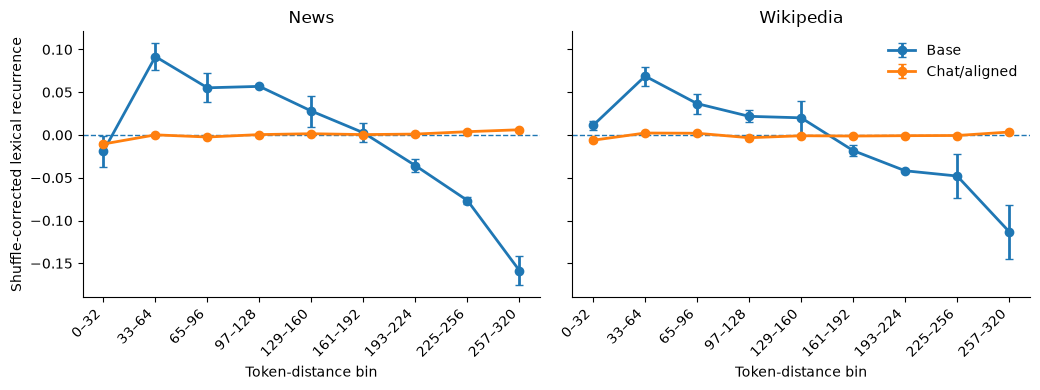

In [3]:
mp=work.groupby(["domain","regime","model"])[bins].mean().reset_index(); x=np.arange(len(bins)); fig,axes=plt.subplots(1,2,figsize=(10.5,4),sharey=True)
for ax,domain in zip(axes,["news","wiki"]):
    for regime in ["Base","Chat/aligned"]:
        s=mp[(mp.domain==domain)&(mp.regime==regime)]; v=s[bins].mean(axis=0).to_numpy(); sem=s[bins].sem(axis=0).to_numpy(); ax.errorbar(x,v,yerr=sem,marker="o",linewidth=2,capsize=3,label=regime)
    ax.axhline(0,ls="--",lw=1); ax.set_xticks(x); ax.set_xticklabels(labels,rotation=45,ha="right"); ax.set_title("News" if domain=="news" else "Wikipedia"); ax.set_xlabel("Token-distance bin"); ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
axes[0].set_ylabel("Shuffle-corrected lexical recurrence"); axes[1].legend(frameon=False); fig.tight_layout(); fig.savefig(FIGURES/"recurrence_distance_profile.pdf",bbox_inches="tight"); fig.savefig(FIGURES/"recurrence_distance_profile.png",dpi=300,bbox_inches="tight"); plt.show()

In [4]:
def boot_mean(vals,n=5000,seed=42):
    vals=np.asarray(vals,float); vals=vals[np.isfinite(vals)]; rng=np.random.default_rng(seed); b=np.array([rng.choice(vals,size=len(vals),replace=True).mean() for _ in range(n)]); lo,hi=np.percentile(b,[2.5,97.5]); return vals.mean(),lo,hi
order=["gpt2","mpt","mistral","llama-chat","chatgpt","gpt4"]; rows=[]
for domain in ["news","wiki"]:
    for i,model in enumerate(order):
        m,l,h=boot_mean(work.loc[(work.domain==domain)&(work.model==model),"token_frontloading"],seed=1000+i); rows.append({"domain":domain,"model":model,"regime":regime_map[model],"mean":m,"ci_low":l,"ci_high":h})
ms=pd.DataFrame(rows); ms.to_csv(RESULTS/"frontloading_by_model.csv",index=False); display(ms)

,domain,model,regime,mean,ci_low,ci_high
0,news,gpt2,Base,0.158165,0.125502,0.189554
1,news,mpt,Base,0.118860,0.084481,0.155511
2,news,mistral,Base,0.112077,0.070775,0.154771
3,news,llama-chat,Chat/aligned,-0.005295,-0.008663,-0.001863
4,news,chatgpt,Chat/aligned,-0.010383,-0.012947,-0.007740
5,news,gpt4,Chat/aligned,-0.008118,-0.010645,-0.005577
6,wiki,gpt2,Base,0.149057,0.108112,0.191474
7,wiki,mpt,Base,0.066324,0.029298,0.102767
8,wiki,mistral,Base,0.107245,0.071207,0.148498
9,wiki,llama-chat,Chat/aligned,0.001382,-0.002188,0.004696


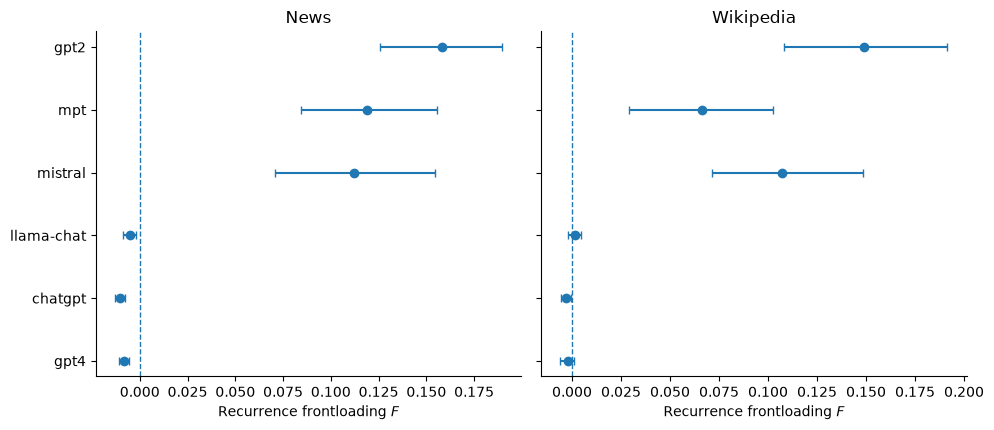

In [5]:
fig,axes=plt.subplots(1,2,figsize=(10,4.4),sharey=True)
for ax,domain in zip(axes,["news","wiki"]):
    s=ms[ms.domain==domain].set_index("model").loc[order].reset_index(); y=np.arange(len(order)); m=s["mean"].to_numpy(); err=np.vstack([m-s.ci_low.to_numpy(),s.ci_high.to_numpy()-m]); ax.errorbar(m,y,xerr=err,fmt="o",capsize=3); ax.axvline(0,ls="--",lw=1); ax.set_yticks(y); ax.set_yticklabels(order); ax.set_title("News" if domain=="news" else "Wikipedia"); ax.set_xlabel(r"Recurrence frontloading $F$"); ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
axes[0].invert_yaxis(); fig.tight_layout(); fig.savefig(FIGURES/"frontloading_by_model.pdf",bbox_inches="tight"); fig.savefig(FIGURES/"frontloading_by_model.png",dpi=300,bbox_inches="tight"); plt.show()

In [6]:
rs=work.groupby(["domain","source_id","regime"])["token_frontloading"].mean().unstack("regime").dropna(); d=(rs["Base"]-rs["Chat/aligned"]).to_numpy(); mean=d.mean(); dz=mean/d.std(ddof=1); print("mean delta:",mean,"paired dz:",dz); pd.DataFrame({"mean_delta_base_chat":[mean],"paired_dz":[dz],"n":[len(d)]}).to_csv(RESULTS/"frontloading_regime_effect.csv",index=False)

mean delta: 0.1227620135702204 paired dz: 1.3441560357278473
